In [35]:
import numpy as np
import pandas as pd
import tensorflow as tf

## Data for simulation

In [36]:
# Time array
t = np.linspace(0, 60, 6000)  # 60 seconds sampled at 100 Hz

# Constants for the simulation
A = 1.0  # Amplitude in arbitrary units
omega_0 = 2 * np.pi / 2.0  # Natural frequency, 2s period
omega_d = 2 * np.pi / 2.2  # Slightly different for damped
tau = 20  # Decay time for damping

# Single pendulum (undamped)
single_pendulum = A * np.cos(omega_0 * t)

# Single pendulum (damped)
damped_pendulum = A * np.exp(-t / tau) * np.cos(omega_d * t)

# In-phase oscillations (both pendula same phase, same freq)
in_phase_1 = A * np.cos(omega_0 * t)
in_phase_2 = A * np.cos(omega_0 * t)

# Out-of-phase oscillations (same amp, opposite sign)
out_phase_1 = A * np.cos(omega_0 * t)
out_phase_2 = -A * np.cos(omega_0 * t)

# Beating (superposition of two similar frequencies)
omega_f = 2 * np.pi / 2.0
omega_c = 2 * np.pi / 1.9
beating = 2 * A * np.cos((omega_c - omega_f) * t / 2) * np.cos((omega_c + omega_f) * t / 2)

# For file 1: single pendulum, damped pendulum
data1 = pd.DataFrame({
    "t": t,
    "single_pendulum": single_pendulum,
    "damped_pendulum": damped_pendulum
})

# For file 2: coupled pendula (in-phase, out-of-phase, beating)
data2 = pd.DataFrame({
    "t": t,
    "in_phase_1": in_phase_1,
    "in_phase_2": in_phase_2,
    "out_phase_1": out_phase_1,
    "out_phase_2": out_phase_2,
    "beating": beating
})

In [37]:
# Add Gaussian noise to each signal
noise_level = 0.05  # Adjust noise level as needed

# Add noise to each column except time
data1_noisy = data1.copy()
for col in data1.columns[1:]:
    data1_noisy[col] += np.random.normal(0, noise_level, size=len(t))

data2_noisy = data2.copy()
for col in data2.columns[1:]:
    data2_noisy[col] += np.random.normal(0, noise_level, size=len(t))

In [38]:
data1_noisy.head()

,t,single_pendulum,damped_pendulum
0,0.000000,0.959455,0.970862
1,0.010002,0.981323,1.048767
2,0.020003,1.014087,0.998476
3,0.030005,0.979430,1.057344
4,0.040007,0.978716,1.084565


rem each col indicate the position of the pendulum  

HOWEVER, THE ACTUAL DATA GIVES ME A WEIRD SCALE, NOT THE AMPLITUDE; DOES IT STILL WORK? WILL TRY  

## Ready-made functions

In [39]:
### Get peaks

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.signal import find_peaks

def get_peaks(x,y):
    '''Pass it t and theta (timestamp and position)'''

    # === 2. Define model for fitting ===
    def damped_oscillator(x, A, lambda_, omega, phi, offset):
        return A * np.exp(-lambda_ * x) * np.sin(omega * x + phi) + offset

    # === 3. Fit the model ===
    # guess = [1.0, 0.1, 2*np.pi, 0.0, 0.0]
    params, _ = curve_fit(damped_oscillator, x, y) # p0=guess
    # A, lambda_, omega, phi, offset = params     HERE ARE THE PARAMS

    # === 4. Evaluate fitted model on dense grid and find peaks ===
    x_dense = np.linspace(x.min(), x.max(), 5000)
    y_fit = damped_oscillator(x_dense, *params)

    peak_indices, _ = find_peaks(y_fit)
    x_peaks = x_dense[peak_indices]
    y_peaks = y_fit[peak_indices]

    plt.figure(figsize=(10,5))
    plt.plot(x, y, '.', label='Data')
    plt.plot(x_dense, y_fit, label='Fitted model')
    plt.plot(x_peaks, y_peaks, 'ro', label='Detected peaks')
    plt.title('Fitting a Damped Oscillator and Finding Peaks')
    plt.xlabel('Time')
    plt.ylabel('Amplitude')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return x_peaks, y_peaks, params

In [40]:
### Plot two pendulums, to examine phase

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.signal import find_peaks


def double_pendulum(x, y1, y2):
    '''Pass timestamps t which is unique, then theta for each pendulum'''

    # === 2. Define model for fitting ===
    def damped_oscillator(x, A, lambda_, omega, phi, offset):
        return A * np.exp(-lambda_ * x) * np.sin(omega * x + phi) + offset

    # === 3. Fit the model ===
    guess = [1.0, 0.1, 2*np.pi, 0.0, 0.0]

    params, _ = curve_fit(damped_oscillator, x, y1, p0=guess)
    A, lambda_, omega, phi, offset = params

    params2, _ = curve_fit(damped_oscillator, x, y2, p0=guess)
    A2, lambda_2, omega2, phi2, offset2 = params2


    # === 4. Evaluate fitted model on dense grid and find peaks ===
    x_dense = np.linspace(x.min(), x.max(), 5000)
    y_fit = damped_oscillator(x_dense, *params)
    y_fit2 = damped_oscillator(x_dense, *params2)


    peak_indices, _ = find_peaks(y_fit)
    x_peaks = x_dense[peak_indices]
    y_peaks = y_fit[peak_indices]


    peak_indices2, _ = find_peaks(y_fit2)
    x_peaks2 = x_dense[peak_indices2]
    y_peaks2 = y_fit2[peak_indices2]



    # === 5. Plot everything ===
    fig = plt.figure(figsize=(10,5))
    ax1, ax2 = fig.subplots(2, 1, sharex=True, gridspec_kw=dict(height_ratios=[1, 1], hspace=0.05))

    ax1.plot(x, y1, '.', label='Noisy data')
    ax1.plot(x_dense, y_fit, label='Fitted model')
    ax1.plot(x_peaks, y_peaks, 'ro', label='Detected peaks')

    ax2.plot(x, y2, '.', label='Noisy data')
    ax2.plot(x_dense, y_fit2, label='Fitted model')
    ax2.plot(x_peaks2, y_peaks2, 'ro', label='Detected peaks')

    ax1.set_xlabel('time')
    ax1.set_ylabel('amplitude')
    ax2.set_ylabel('amplitude')
    ax1.grid()
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.show()

    return x_peaks, y_peaks, params, x_peaks2, y_peaks2, params2

In [62]:
### Plot battimenti

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.optimize import curve_fit

def beat_model(t, A, omega_m, phi_m, omega_b, phi_b, offset):
    return A * np.cos(omega_m * t + phi_m) * np.cos(omega_b * t + phi_b) + offset

def get_peaks_beat(t, y):
    '''Pass it t and theta'''

    # Fit the beat model
    # You can adjust the initial guess depending on your data
    guess = [1.0, 2*np.pi*10, 0.0, 2*np.pi*1, 0.0, 0.0]  # A, ω_m, φ_m, ω_b, φ_b, offset
    params, _ = curve_fit(beat_model, t, y, p0=guess)

    # Generate fitted curve
    t_dense = np.linspace(t.min(), t.max(), 5000)
    y_fit = beat_model(t_dense, *params)

    # Find peaks
    peaks_idx, _ = find_peaks(y_fit)
    t_peaks = t_dense[peaks_idx]
    y_peaks = y_fit[peaks_idx]

    # Plot
    plt.figure(figsize=(10,5))
    plt.plot(t, y, '.', label='Original data')
    plt.plot(t_dense, y_fit, label='Fitted beat model')
    plt.plot(t_peaks, y_peaks, 'ro', label='Peaks')
    plt.title('Beat signal: fit and peak detection')
    plt.xlabel('Time')
    plt.ylabel('Amplitude')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return t_peaks, y_peaks, params


## Simple pendulum, undamped

### Find peaks

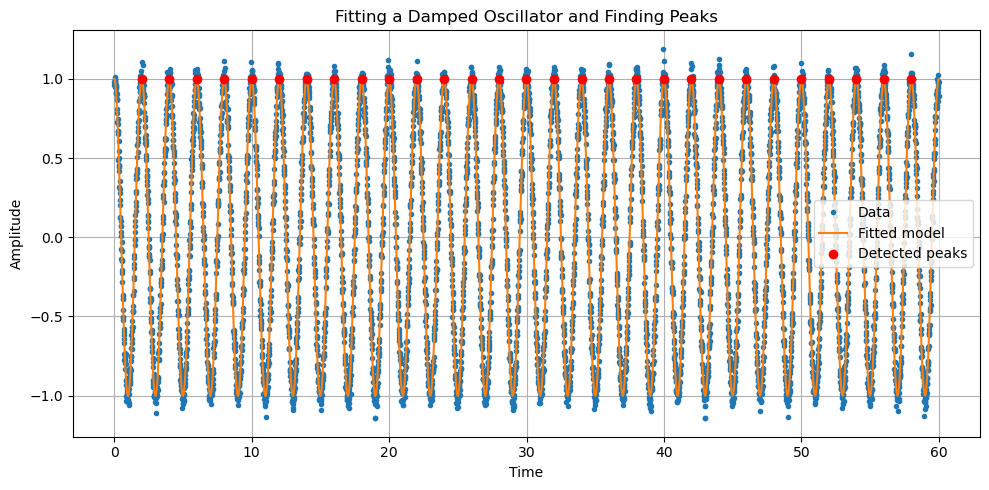

In [42]:
x = data1_noisy.t
y = data1_noisy.single_pendulum

t_simple, theta_simple, _= get_peaks(x,y)

no: for uncertainty, simply decide where to truncate and put that as uncertainty???  
try to adjust ???  

In [43]:
# Uncertainty in x_peaks

# Estimate residual noise
# residuals = y - damped_oscillator(x, *params)
# noise_std = np.std(residuals)

# Estimate spacing in x_dense
# delta_x = x_dense[1] - x_dense[0]

# Signal-to-noise ratio at peak
# SNR = np.max(np.abs(y_peaks)) / noise_std

# Crude uncertainty estimate for each peak (same for simplicity)
#x_peak_uncertainty = delta_x / np.sqrt(SNR)  # this is the uncertainty  

### Find period and pulsation

In [44]:
period = np.array([t_simple[i+1] - t_simple[i] for i in range(len(t_simple)-1)])  

In [45]:
# Compute omega and uncertainty  

def f(T):
    return 2*np.pi/T

T = tf.Variable(np.mean(period)) 

with tf.GradientTape(persistent=True) as tape:
    tape.watch([T])  
    omega = f(T)

df_dT = tape.gradient(omega, T)

err_omega = (df_dT * np.std(period))**2

In [46]:
omega = omega.numpy()
err_omega = err_omega.numpy()

## Simple damped pendulum

### Find peaks

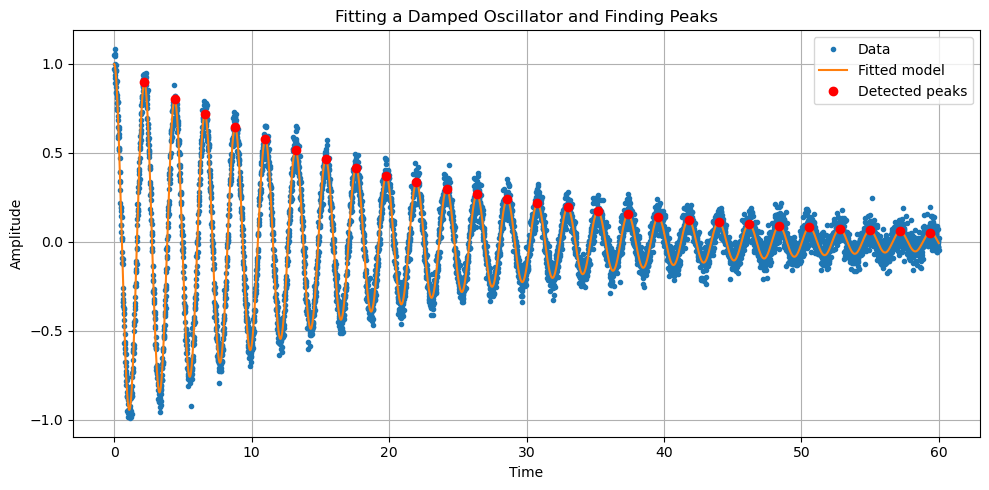

In [47]:
x = data1_noisy.t
y = data1_noisy.damped_pendulum

t_damped, theta_damped, params= get_peaks(x,y)

In [48]:
print(1/params[1])

20.046696181835873


### Extimate decay time

teorically could have gotten it from previous fit as well, but this is logarithmic scale?  

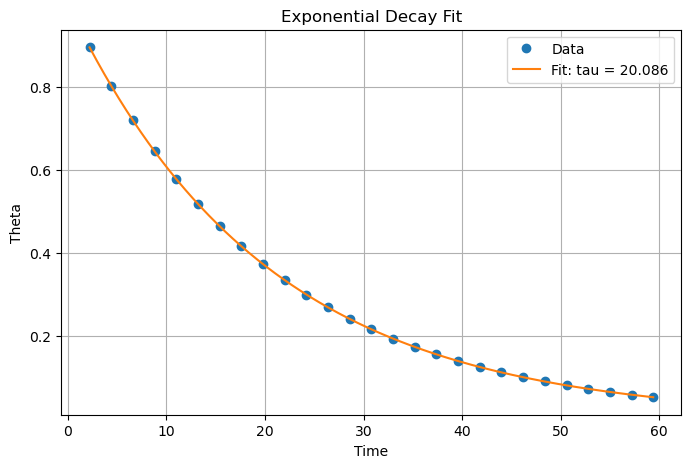

Estimated tau: 20.08586984692903


In [49]:
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt

# t = data1_noisy.t
# theta = data1_noisy.damped_pendulum

t = np.array(t_damped)        # Time values
theta = np.array(theta_damped)    # Corresponding theta values

def exponential_decay(t, theta0, tau):
    return theta0 * np.exp(-t / tau)

# guess = [theta[0], 1.0]
params, cov = curve_fit(exponential_decay, t, theta)  # po =g guess
theta0_fit, tau_fit = params


# Plot it
t_dense = np.linspace(t.min(), t.max(), 1000)
theta_fit = exponential_decay(t_dense, *params)

plt.figure(figsize=(8, 5))
plt.plot(t, theta, 'o', label='Data')
plt.plot(t_dense, theta_fit, label=f'Fit: tau = {tau_fit:.3f}')
plt.xlabel('Time')
plt.ylabel('Theta')
plt.title('Exponential Decay Fit')
plt.legend()
plt.grid(True)
plt.show()

print(f"Estimated tau: {tau_fit}")

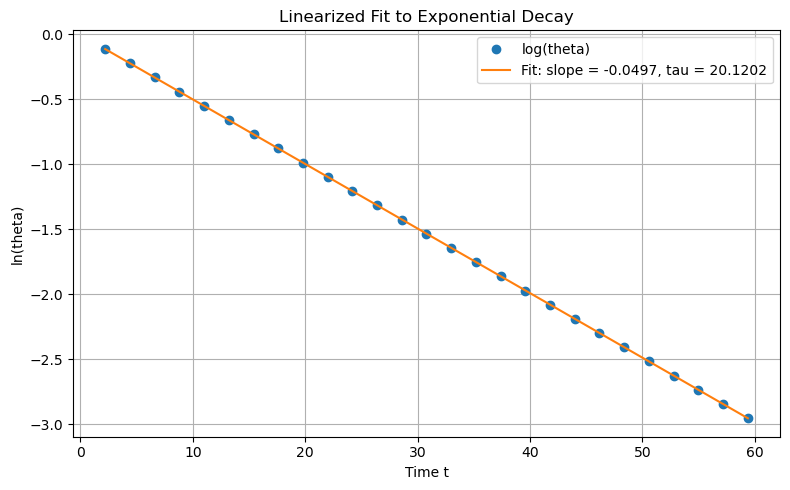

Estimated tau: 20.1202
Standard error on slope: 0.0000
Uncertainty on tau: 0.0056


In [50]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Could also use these, but it's messier, like this it0s prettier
# t = data1_noisy.t
# theta = data1_noisy.damped_pendulum


t = np.array(t_damped)        # Time values
theta = np.array(theta_damped)    # Corresponding theta values

# === Remove zero or negative values to avoid log issues ===
mask = theta > 0
t = t[mask]
theta = theta[mask]

# === Log-transform ===
log_theta = np.log(theta)

# === Linear fit ===
slope, intercept, r_value, p_value, std_err = linregress(t, log_theta)
tau = -1 / slope

# === Plot ===
plt.figure(figsize=(8,5))
plt.plot(t, log_theta, 'o', label='log(theta)')
plt.plot(t, intercept + slope * t, label=f'Fit: slope = {slope:.4f}, tau = {tau:.4f}')
plt.xlabel('Time t')
plt.ylabel('ln(theta)')
plt.title('Linearized Fit to Exponential Decay')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# === Result ===
print(f"Estimated tau: {tau:.4f}")
print(f"Standard error on slope: {std_err:.4f}")
print(f"Uncertainty on tau: {abs(std_err / slope**2):.4f}")


i have theta(t) and t, how to fit tau? is it possible to do a linear fit in a log scale, so that tau is the pendence of the line?

### Check period

In [51]:
period_damped = np.array([t_damped[i+1] - t_damped[i] for i in range(len(t_damped)-1)])  

In [52]:
print(f'Undamped period: {np.mean(period)} \n' 
      f'Damped period: {np.mean(period_damped)}')

Undamped period: 1.9996856514159975 
Damped period: 2.199670703371443


## Obscillations phase

### In phase

/tmp/ipykernel_5198/1212783259.py:61: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


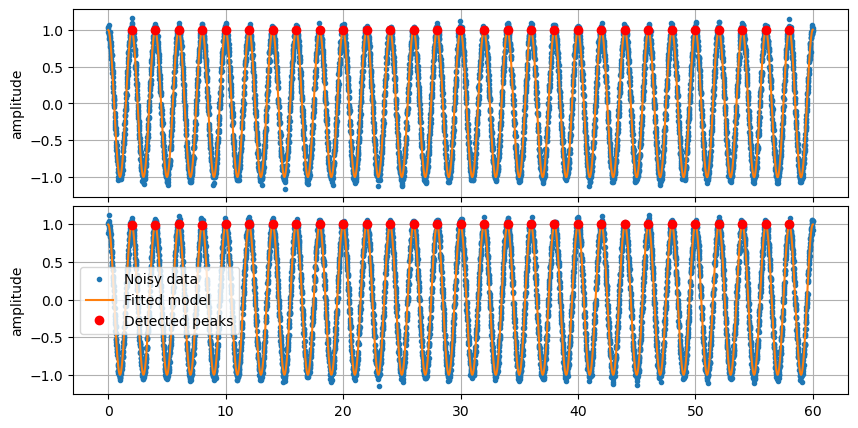

In [53]:
x = data2_noisy.t
y = data2_noisy.in_phase_1
y2 = data2_noisy.in_phase_2

t1, theta1, param1, t2, theta2, param2 = double_pendulum(x,y,y2)

In [54]:
omega_phase = (param1[2], param2[2])
print(f'Pulsations are: {omega_phase[0]}, {omega_phase[1]}')

Pulsations are: 3.141550760583311, 3.1415193801411863


### In controphase

/tmp/ipykernel_5198/1212783259.py:61: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


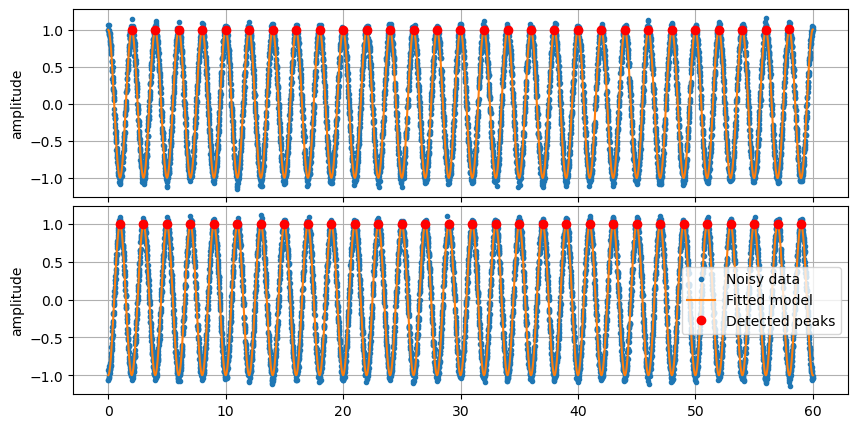

In [55]:
x = data2_noisy.t
y = data2_noisy.out_phase_1
y2 = data2_noisy.out_phase_2

t1, theta1, param1, t2, theta2, param2 = double_pendulum(x,y,y2)

In [56]:
omega_not_phase = (param1[2], param2[2])
print(f'Pulsations are: {omega_not_phase[0]}, {omega_not_phase[1]}')

Pulsations are: 3.1416985591602224, 3.1416396007294938


boh, need real ones to check???  

## Battimenti

only need to plot one pendulum, if want can plot 2, but whatever  

In [78]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import hilbert, find_peaks
from scipy.fft import fft, fftfreq

def analyze_beats(t, y):
    dt = t[1] - t[0]
    fs = 1 / dt
    N = len(t)

    # === 1. FFT to find dominant frequencies ===
    yf = fft(y)
    freqs = fftfreq(N, d=dt)
    idx = np.argsort(np.abs(yf[:N//2]))[::-1]  # Sort by magnitude

    # Take the two strongest positive frequencies
    dominant_freqs = freqs[idx[:2]]
    dominant_freqs = np.abs(dominant_freqs)
    omega1, omega2 = 2 * np.pi * dominant_freqs

    # === 2. Estimate ω_m and ω_b ===
    omega_m = (omega1 + omega2) / 2
    omega_b = abs(omega1 - omega2) / 2

    # === 3. Construct carrier and envelope ===
    carrier = np.cos(omega_m * t)
    envelope = np.abs(hilbert(y))  # analytical signal gives envelope

    # === 4. Plot ===
    plt.figure(figsize=(10, 6))
    plt.plot(t, y, label='Original signal')
    plt.plot(t, envelope, 'r--', label='Envelope (modulante)')
    plt.plot(t, -envelope, 'r--')
    plt.plot(t, carrier, 'g:', label='Carrier (portante)')
    plt.xlabel('Time')
    plt.ylabel('Amplitude')
    plt.title('Battimenti')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    print(f"Estimated omega1 = {omega1:.3f} rad/s")
    print(f"Estimated omega2 = {omega2:.3f} rad/s")
    print(f"=> omega_m (carrier) = {omega_m:.3f} rad/s")
    print(f"=> omega_b (envelope) = {omega_b:.3f} rad/s")

    return omega_m, omega_b



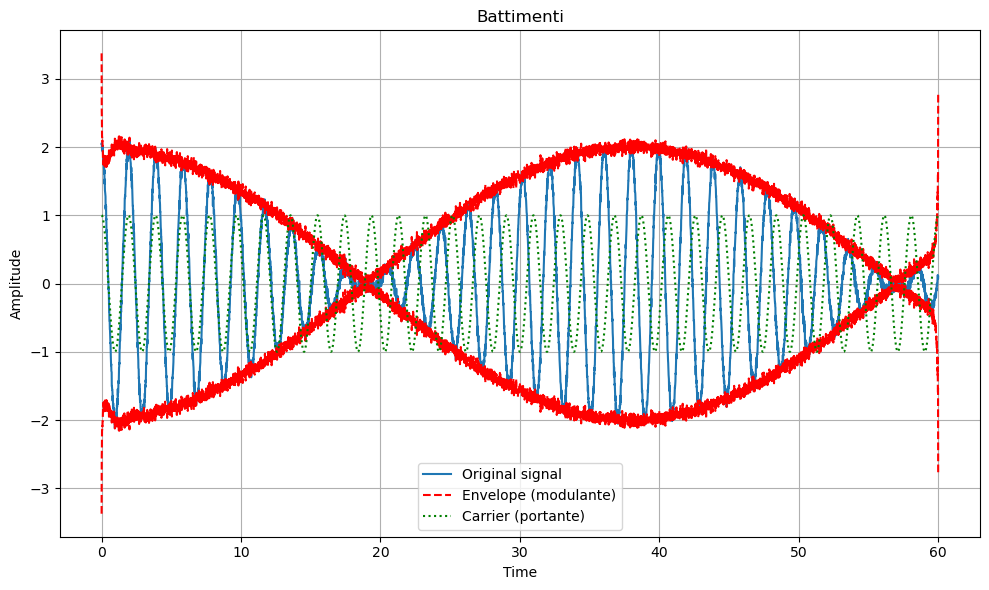

Estimated omega1 = 3.141 rad/s
Estimated omega2 = 3.350 rad/s
=> omega_m (carrier) = 3.246 rad/s
=> omega_b (envelope) = 0.105 rad/s


In [79]:
x = data2_noisy.t
y = data2_noisy.beating

x = np.array(data2_noisy.t)
y = np.array(data2_noisy.beating)

om1, om2 = analyze_beats(x,y)